# Grupparbete - Grupp 3
# Försäljningsanalys

## 1. Introduktion

Denna rappor är att analysera försäljningsdata

- Analysen perioden är januari-juni 2024 och fokuserar på viktiga nyckeltal som totala intäkter, antal sålda och AOV. 

- Resultaten används för att identifiera skillnader i försäljningen och ge rekommendationer. 


In [1]:
# Importerar lib för att hantera filer och sökvägar
import sys
from pathlib import Path

# går upp en nivå i projektets mapp
sys.path.insert(0,"..")

# Hämtar lib för att sen kunna importera
project_root = Path.cwd().resolve()

# går upp en nivå i mappen struktur för att kunna importera src fil

if project_root.name == "notebooks":
    project_root = project_root.parent


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# importerar funktioner från src filen

from src.io_utils import load_data, process_data

## 2. Dataimport och databearbetning

- Data läses in från filen ecommerce_sales.csv med hjälp av funktion load_data().

- Sen med process_data() konverteras datumkolumnen till datetime format. 

In [3]:
# Läser in data från CSV filen
df = load_data("../data/ecommerce_sales.csv")

df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [4]:
# Arbeta data och convertera dtypes som behövs
df = process_data(df)

df.dtypes

order_id             int64
date        datetime64[us]
city                   str
category               str
price              float64
units                int64
revenue            float64
dtype: object

In [5]:
# Kontrollerar om det finns null värdet

print("Null värden: ")
df.isnull().sum()

Null värden: 


order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64

In [6]:
# Kontrollerar hur många duplicerade rader som finns 

print("Duplicerade rader: ", df.duplicated().sum())

Duplicerade rader:  0


### 2.1 Datakvalitet

- Vi kan se att i dataset finns inga Null värden och inga duplicerade rader.
- Vi ser också att alla kolumnen är i rättdatatype

## 3 Nyckeltal 

### 3.1 Försäljningens nyckeltal

In [7]:
# importera funktionern för att beräkna KPI
from src.kpi__metrics import order_stat

import numpy as np

In [8]:
# Breäknar orderstatistik med funktion 

resultat = order_stat(df)

# Hämtar nyckeltalen från funktionen order_stat (kpi__metrics.py)
order_tot, revenue_tot, units_tot, aov, revenue_max, revenue_median, revenue_min = order_stat(df)

kpi_df = pd.DataFrame(
    {
        "KPI": [
            "Totalt antal ordrar",
            "Totalt intäkter (SEK)",
            "Totalt sålda enheter",
            "Genomsnittligt ordervärde (Kr)",
            "Högsta ordervärde (SEK)",
            "Medianordervärde (SEK)",
            "Lägsta ordervärde (SEK)",
        ],
        "Värde": [
            order_tot,
            revenue_tot,
            units_tot,
            aov,
            revenue_max,
            revenue_median,
            revenue_min,
        ],
    }
)

display(kpi_df.round(2))


,KPI,Värde
0,Totalt antal ordrar,2500.00
1,Totalt intäkter (SEK),3502767.23
2,Totalt sålda enheter,7463.00
3,Genomsnittligt ordervärde (Kr),1401.11
4,Högsta ordervärde (SEK),9192.60
5,Medianordervärde (SEK),1088.69
6,Lägsta ordervärde (SEK),50.00


### Analys av nyckeltal

- Det är registretades totalt 2 500 order och 7 463 sålda enheter med en intäkt på cirka 3,5 miljoner SEK.
  
- Det genomsnitt ordervärdet (AOV) var 1 401,11 SEK, medan medianordevördet var 1 088,69 SEK.

- Ordervärdet minsta är 50 SEK och högsta är 9 192,60 SEK.

### 3.2 Fördelning av odervärden

In [9]:
# Skapar 20 jämt delar gränser mellan min och max intäkter

buckets = np.linspace(revenue_min, revenue_max, 20)

# Räknar antalet ordrar i varje intervall 
revenue_distr = (
    pd.crosstab(
        df["order_id"],
        pd.cut(df["revenue"], bins=buckets, right=True, include_lowest=True, precision=2),
    )
    .sum()
    .sort_index()
)
display(revenue_distr)

revenue
(49.99, 531.19]       564
(531.19, 1012.38]     609
(1012.38, 1493.57]    454
(1493.57, 1974.76]    289
(1974.76, 2455.95]    216
(2455.95, 2937.14]    119
(2937.14, 3418.33]     88
(3418.33, 3899.52]     51
(3899.52, 4380.71]     31
(4380.71, 4861.89]     28
(4861.89, 5343.08]     19
(5343.08, 5824.27]     12
(5824.27, 6305.46]     11
(6305.46, 6786.65]      4
(6786.65, 7267.84]      1
(7267.84, 7749.03]      1
(8230.22, 8711.41]      2
(8711.41, 9192.6]       1
dtype: int64

In [10]:
# Kollar att alla odrar ingrår 
print("Totalt antal ordrar: ", order_tot)
print("Ordrar i intervall: ", revenue_distr.sum())

Totalt antal ordrar:  2500
Ordrar i intervall:  2500


### Analys av ordervärdenas fördelning

- Det visar att de flesta ordrarna har relativt låga ordervärden. 

- Det vanligaste ligger mellan cirka 531 och 1 013 SEK med 609 ordrar. 

- Antalet ordrar minskar generellt när ordervädret ökar. 

In [11]:
# Räknar totala intäkter per produktkategori

from src.kpi__metrics import (calculate_city_revenue, compare_city_revenue, print_city_revenue_summary)

### 3.3 Intäkter per stad

In [12]:
# Totala intäkter per stad
city_revenue = calculate_city_revenue(df)

display(city_revenue)

city
Stockholm    1227201.94
Göteborg      859019.65
Malmö         567926.32
Uppsala       551478.42
Västerås      297140.90
Name: revenue, dtype: float64

In [13]:
# Jamför staden med högsta och lägsta intäkter 
comparison = compare_city_revenue(city_revenue)

print_city_revenue_summary(comparison)

Staden med högst intäkt: Stockholm, 1 227 201,94 kr
Staden med lägst intäkt: Västerås, 297 140,90 kr
Skillnad: 930 061,04 kr
Förhållande: 4,13


### Analys av intäkter per stad

- Stockholm genererar högst försälning med cirka 1,23 miljoner kr

- Västerår har lägst med cirka 297 000 kr. 

- Skillnaden mellan dem är 930 000 kr, stockholm generar ungefär 4,13 gånger mer en Västerås


### 3.4 Intäkter per kategori

In [14]:
from src.metrics import revenue_by_category

In [15]:
category_revenue = revenue_by_category(df)

display(category_revenue)

,category,total_intäkter
0,Electronics,1364228.07
1,Sports,734653.42
2,Clothing,586744.91
3,Home,511070.87
4,Beauty,163053.97
5,Toys,143015.99


In [16]:
top_categories = category_revenue.head(3)

display(top_categories)

,category,total_intäkter
0,Electronics,1364228.07
1,Sports,734653.42
2,Clothing,586744.91


In [17]:
from src.diagram_viz import diagram_1

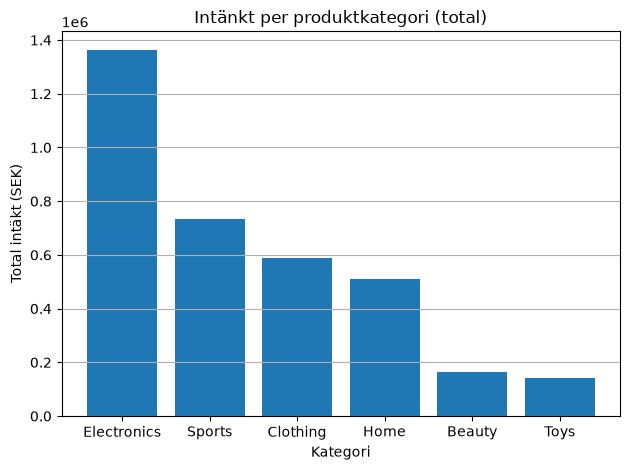

In [18]:
diagram_1(df)

#### Analys av diagrammet

Det visar att Electronics är den kategori som generar högtst försäljningintäkter, med cirka 1,36 miljoner SEK.

Sport och Clothing följer på andra respektive tredje plats.

Beauty och Toys är minsta och dem är ganska lika. 

Electronics står för en betydligt stööre del av den totala intäkter. 


### 3.5 Försäjlning över tid

In [19]:
from src.metrics import (monthly_sales, weekly_sales,monthly_growth,sales_trends)

In [20]:
# Räkna de totala försäljningsintäkterna per månad
monthly_sales_data = monthly_sales(df)

display(monthly_sales_data)

date
2024-01    664083.32
2024-02    548462.03
2024-03    487602.00
2024-04    580194.83
2024-05    632165.16
2024-06    590259.89
Freq: M, Name: revenue, dtype: float64

In [21]:
trends = sales_trends(df)
display(trends)

{'highest_month': '2024-01',
 'highest_sales': np.float64(664083.32),
 'lowest_month': '2024-03',
 'lowest_sales': np.float64(487602.0)}

In [22]:
growth = monthly_growth(df)
display(growth.round(2))

date
2024-01      NaN
2024-02   -17.41
2024-03   -11.10
2024-04    18.99
2024-05     8.96
2024-06    -6.63
Freq: M, Name: revenue, dtype: float64

In [23]:
weekly_revenue = weekly_sales(df)

display(weekly_revenue.round(2))

date
2024-01-07    161119.04
2024-01-14    136568.68
2024-01-21    147225.11
2024-01-28    165832.80
2024-02-04    124154.34
2024-02-11    129235.14
2024-02-18    120294.76
2024-02-25    130817.18
2024-03-03    135071.28
2024-03-10    125966.50
2024-03-17    109400.74
2024-03-24     99852.72
2024-03-31    114609.06
2024-04-07    117292.87
2024-04-14    146409.48
2024-04-21    157775.20
2024-04-28    123154.55
2024-05-05    140330.00
2024-05-12    139988.87
2024-05-19    123365.13
2024-05-26    156746.92
2024-06-02    144516.63
2024-06-09    166384.34
2024-06-16    109619.70
2024-06-23    134604.41
2024-06-30    142431.78
Freq: W-SUN, Name: revenue, dtype: float64

### 3.6 Visualisering av försäljning över tid

In [24]:
from src.viz import plot_sales_over_time

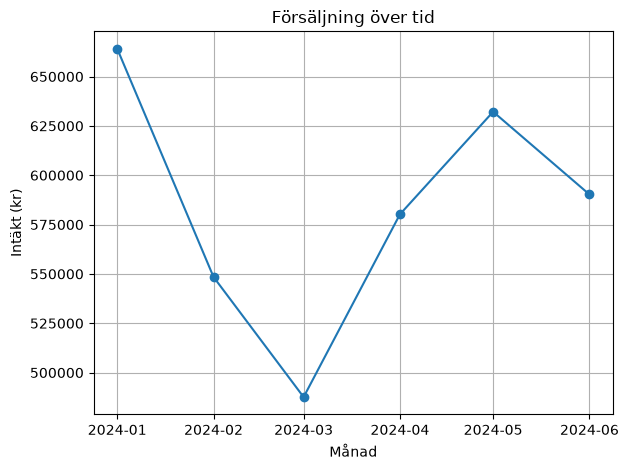

In [25]:
fig,ax = plot_sales_over_time(df)

plt.show()

### Analys av försäljning över tid

Försäljingintäkterna varierade under perdionde

**Månadsförsäljning:** Januari hade de högsta intäkterna med cirka 664 083 SEK, medan mars hade lägsta med 487 602 SEK.

- Diagrammet visar en tydlig nedgång under februari och mars. Följt av en återhämtning i april och maj. 

**Månatlig förandring.** Försäljningen minskade med 17,41% i februari och 11,10 i mars respektiv med februari. Sen ökade med 18,99% i april respektiv med mars.

**Veckoförsäljning:** Högdta vecka var veckan som avslutades 9 Juni, med cirka 166 383 SEK. Lägsta va den som slutade 24 mars med 99 853 SEK.

## 4. Rekommendationer

### 1. Satsa på Electronics

Electronics är den kategori som generar högst intäkter. Företaget bör undersöka att stärka denna kategori genom till exempel marknadsföringstrattegier. 

### 2. Undersök försäljningsskillnader mellan städer

Stockholm genererar cirka 4 gånger högre än Västerås. Det bör undersöka om skillnaden beror på antalet kunder , antalet av order eller om det är lokala faktorer seom beror på. 

### 3. Analysera perioder med lägre försäljning

Mars hade lägsta försäljningsintäkter med cirka 488 000 SEK. Det bör undersöka orsaker till den 17% negånger och till exempel jämföra resultates med tidigare år, analysera till exempel om det satsar mindre pengar i marknadsforing eller om det beror på nångting annat. 